In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 12

# Exercise 1

Simpson rule: 1.718284154699897
Analytical: 1.718281828459045
Error: 1.35e-06 %



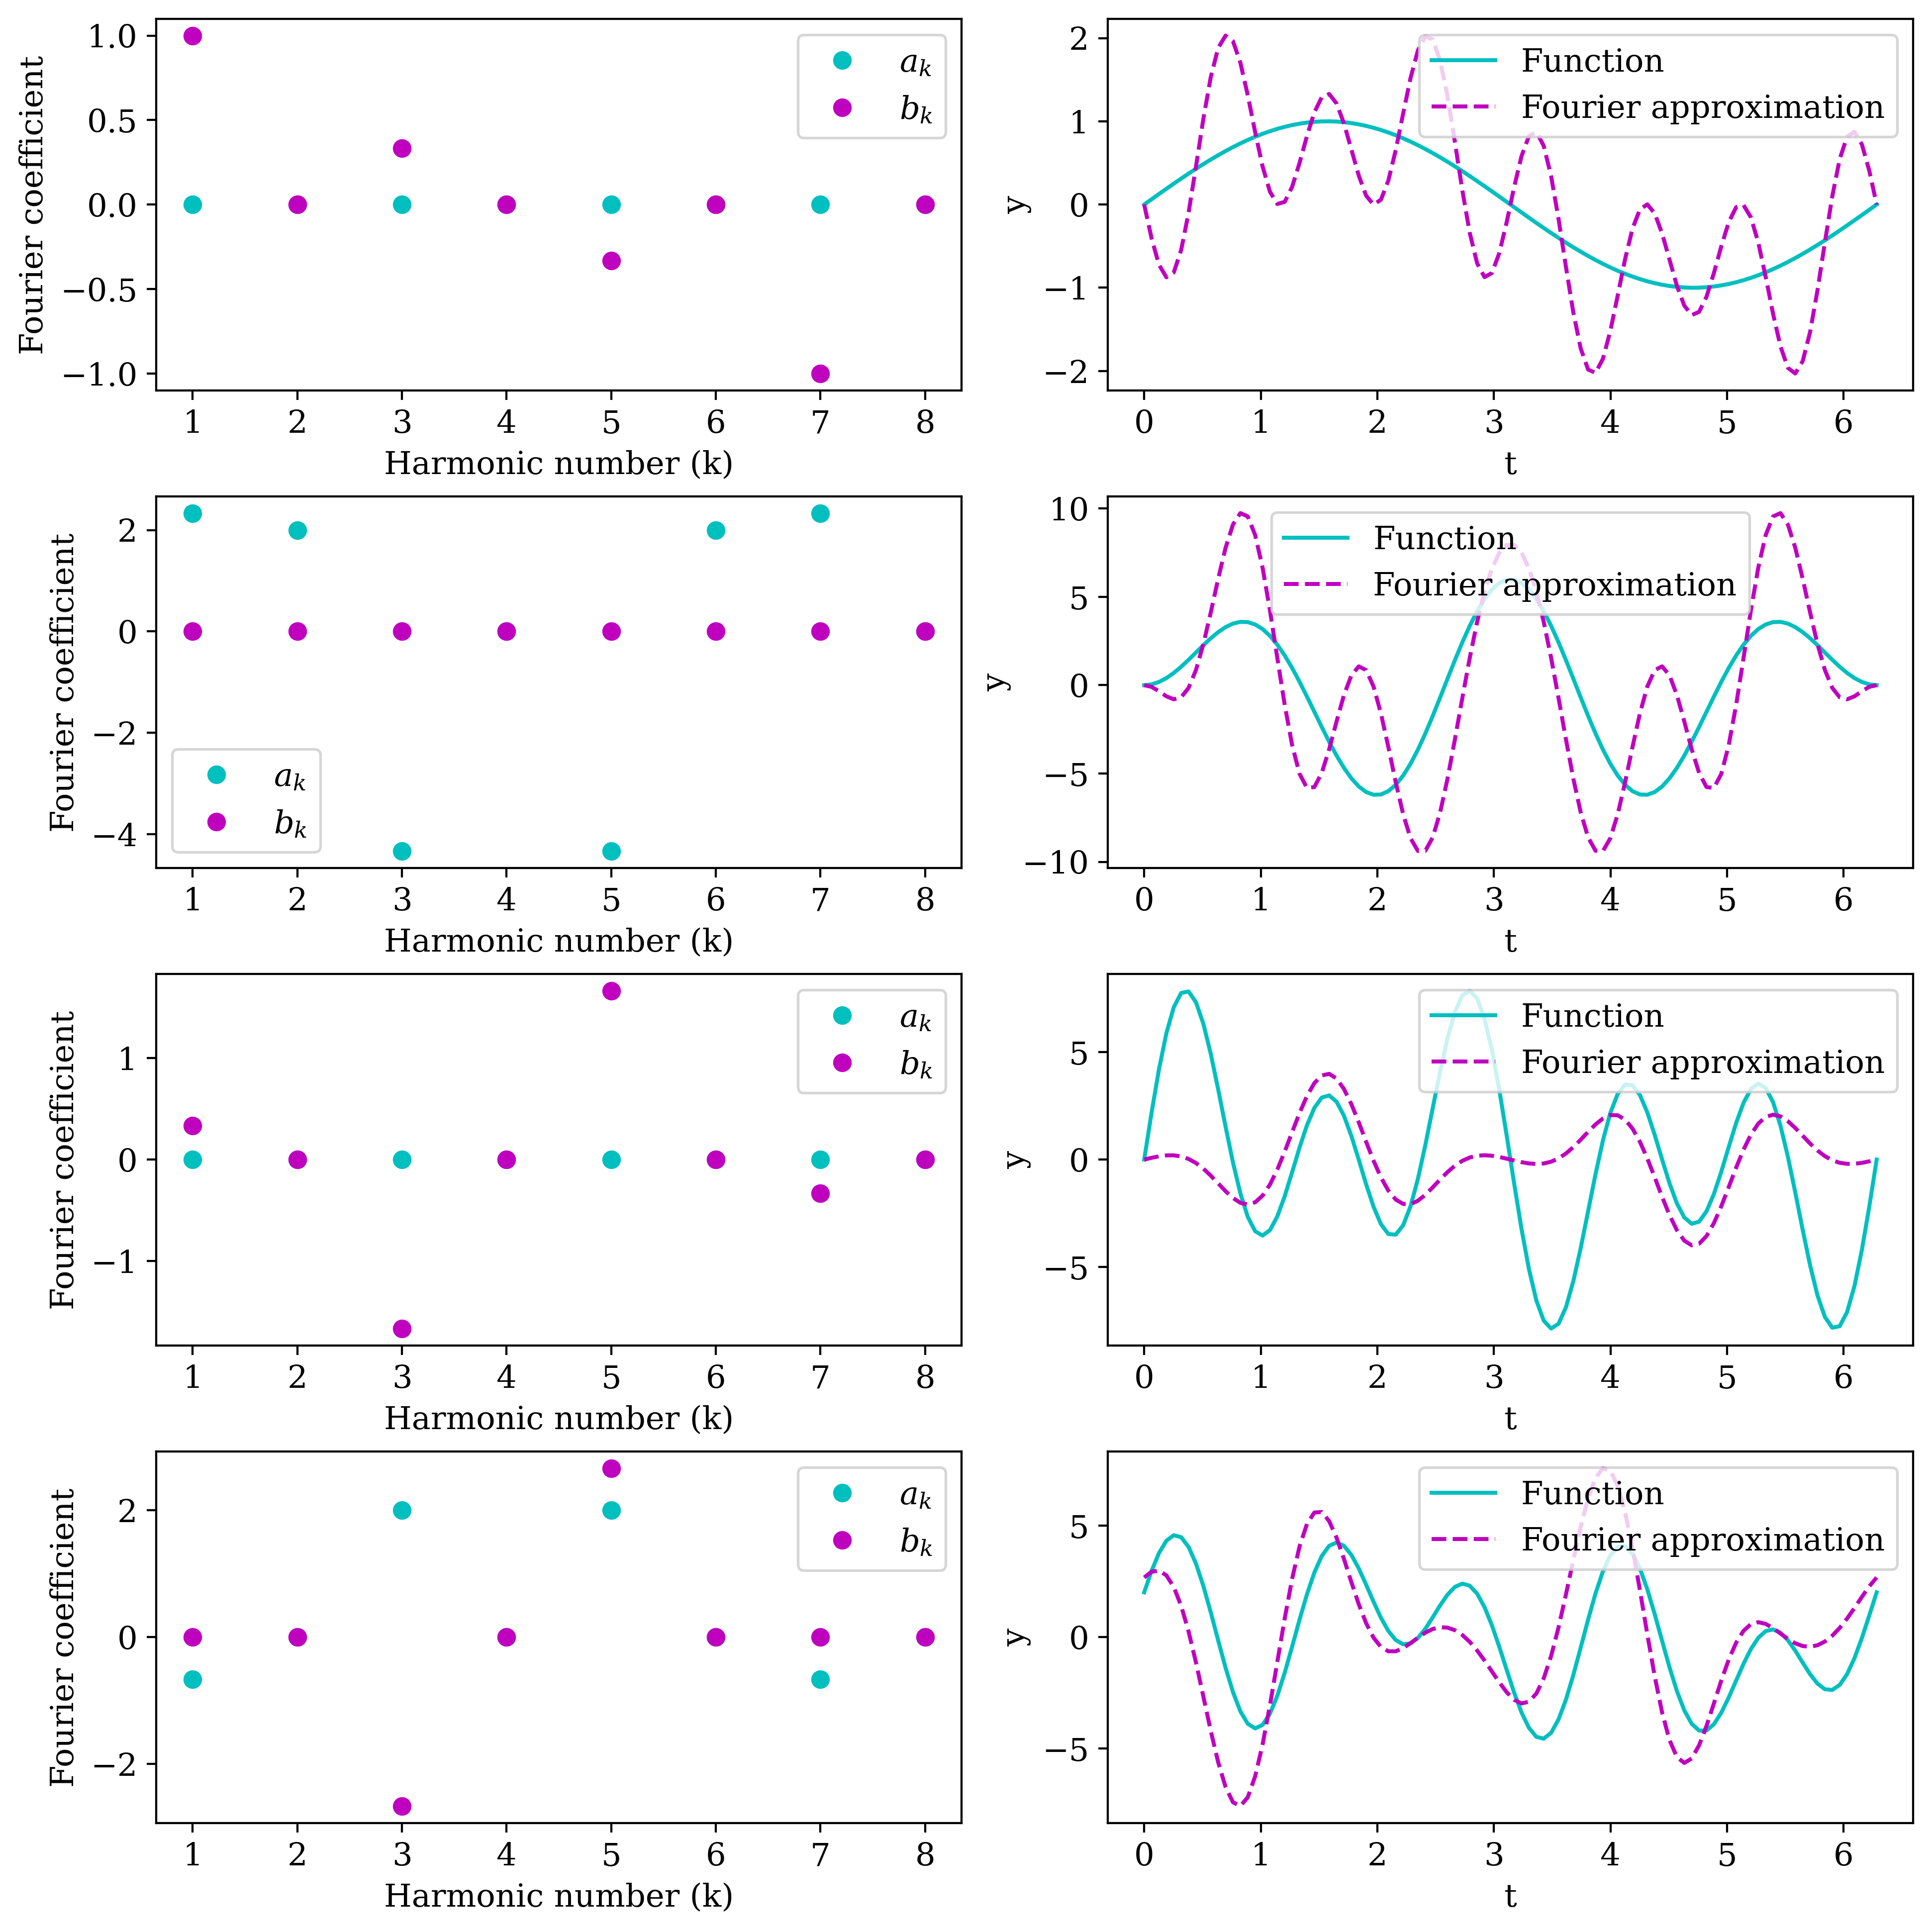

In [2]:
def simpson(f, a, b, n):
  h = (b - a) / n

  return (h / 3) \
          * (f(a) + 2 * sum(f(a + 2 * j * h) for j in range(1, n//2))
          + 4 * sum(f(a + (2 * j - 1) * h) for j in range(1, n//2 + 1))
          + f(b))


result = simpson(np.exp, 0, 1, 8)
G = np.e - 1

print(f'Simpson rule: {result}')
print(f'Analytical: {G}')
print(f'Error: {np.abs(result - (G)) / (G):.3} %\n')


def a_0(f, T, n):
  return (1 / T) * simpson(f, 0, T, n)


def a_k(f, T, ω, k, n):
  F = lambda t: f(t) * np.cos(k * ω * t)
  return (2 / T) * simpson(F, 0, T, n)


def b_k(f, T, ω, k, n):
  F = lambda t: f(t) * np.sin(k * ω * t)
  return (2 / T) * simpson(F, 0, T, n)


def plot_compare(f, T, ω, n, ax):
  ax[0].plot(ks, [a_k(f, 2*np.pi, ω, k, 8) for k in ks], 'co', label='$a_k$')
  ax[0].plot(ks, [b_k(f, 2*np.pi, ω, k, 8) for k in ks], 'mo', label='$b_k$')
  ax[0].set_xlabel('Harmonic number (k)')
  ax[0].set_ylabel('Fourier coefficient')
  ax[0].legend()

  ts = np.linspace(0, T, num=100)

  ys_approx = a_0(f, T, n) + sum(a_k(f, T, ω, k, n) * np.cos(k * ω * ts)
              + b_k(f, T, ω, k, n) * np.sin(k * ω * ts)
              for k in range(1, n + 1))

  ax[1].plot(ts, f(ts), label='Function', color='c')
  ax[1].plot(ts, ys_approx, 'm--', label='Fourier approximation')
  ax[1].set_xlabel('t')
  ax[1].set_ylabel('y')
  ax[1].legend()


ks = np.arange(1, 9)
ω = 1

funcs = [lambda t: np.sin(ω * t),
         lambda t: np.cos(ω * t) + 3 * np.cos(2 * ω * t)
         - 4 * np.cos(3 * ω * t),
         lambda t: np.sin(ω * t) + 3 * np.sin(3 * ω * t)
         + 5 * np.sin(5 * ω * t),
         lambda t: np.sin(ω * t) + 2 * np.cos(3 * ω * t)
         + 3 * np.sin(5 * ω * t)]

fig, axs = plt.subplots(4, 2, figsize=(10, 10), constrained_layout=True,
                        dpi=384)

for F, ax in zip(funcs, axs):
  plot_compare(F, 2 * np.pi, ω, 8, ax)

plt.savefig('compare.png', bbox_inches='tight')
plt.show()

# Exercise 2

k=1, a=0.03, b=1.27, true b=1.27
k=2, a=-0.00, b=-0.00, true b=0.00
k=3, a=0.03, b=0.42, true b=0.42
k=4, a=0.00, b=0.00, true b=0.00
k=5, a=0.03, b=0.25, true b=0.25




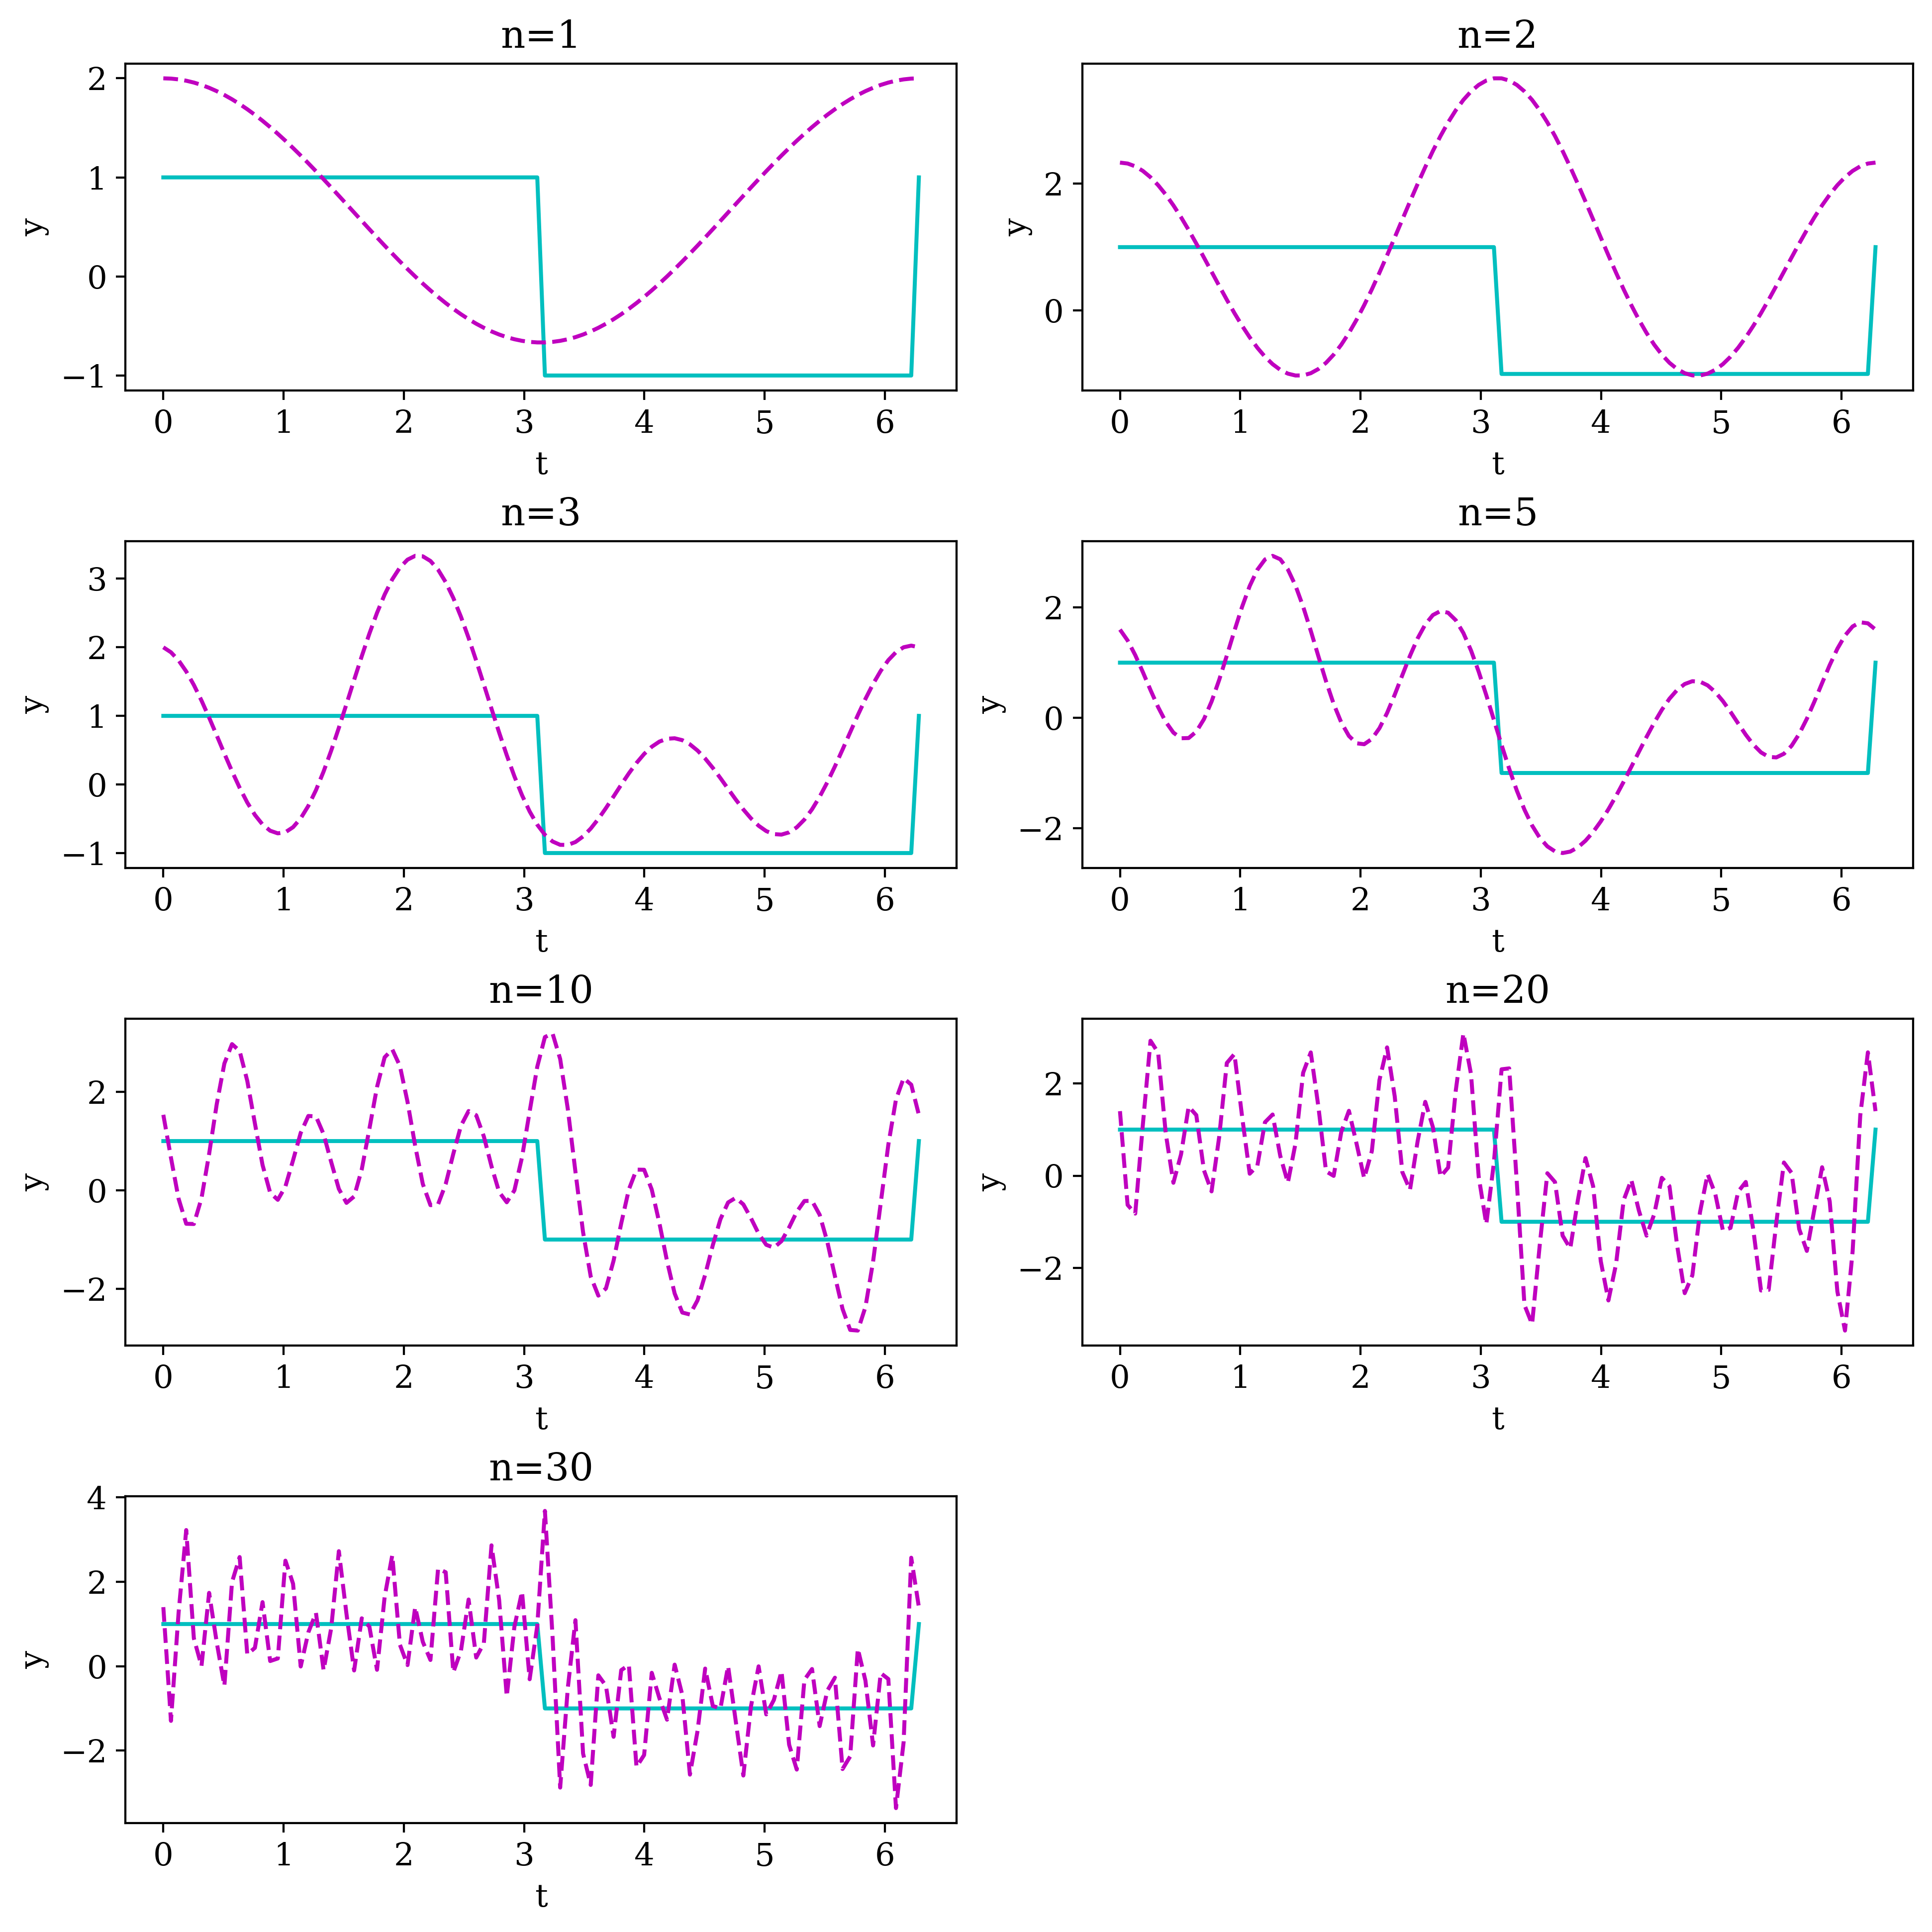


a0=-0.68, true a0=-0.50
k=1, a=0.54, true a=0.64, b=0.28, true b=0.64
k=2, a=0.31, true a=0.00, b=0.44, true b=0.64
k=3, a=0.05, true a=-0.21, b=0.42, true b=0.21
k=4, a=-0.10, true a=-0.00, b=0.27, true b=0.00
k=5, a=-0.11, true a=0.13, b=0.10, true b=0.13




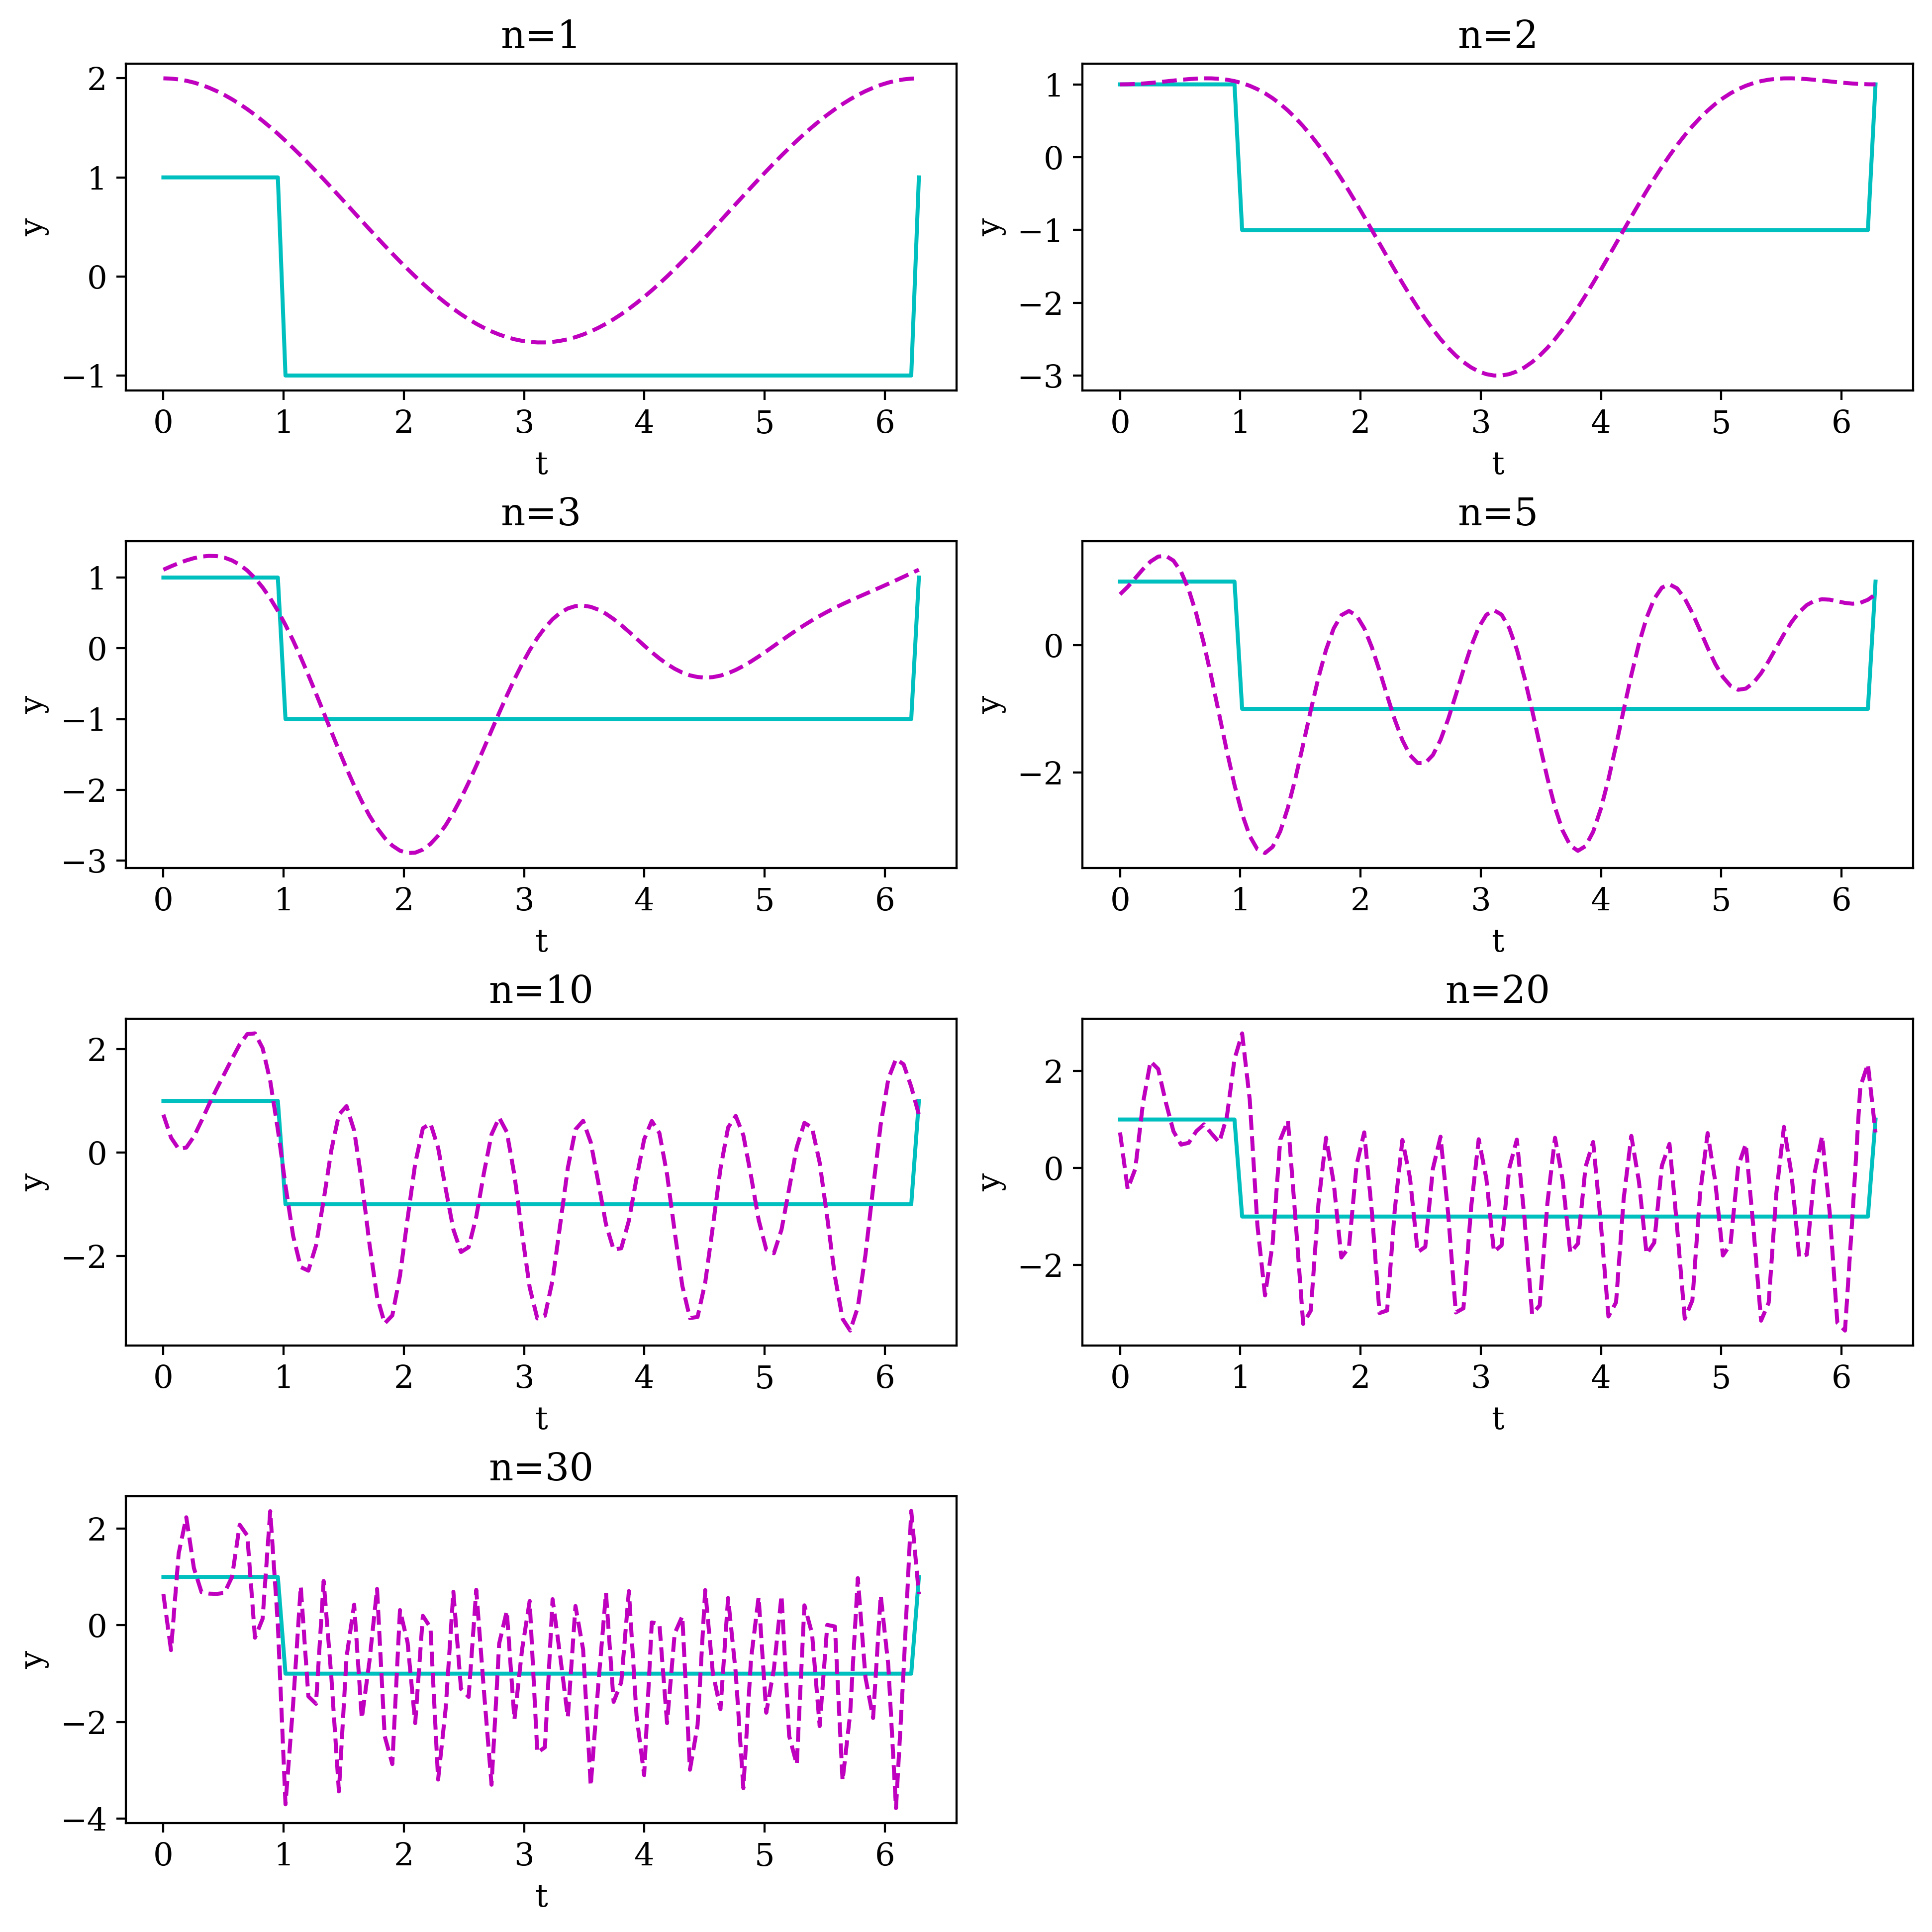

In [3]:
def square_wave(t, ω=1):
  θ = (ω * t) % (2 * np.pi)

  return 1 if θ <= np.pi else -1


for k in range(1, 6):
  true_bk = 0 if k % 2 == 0 else 4 / (np.pi * k)

  print(f'k={k}, a={a_k(square_wave, 2 * np.pi, ω, k, 100):.2f}, '
  f'b={b_k(square_wave, 2 * np.pi, ω, k, 100):.2f}, true b={true_bk:.2f}')

print('\n')


def fourier_series(f, T, ω, n, t):
  return a_0(f, T, n) + sum(a_k(f, T, ω, k, n) * np.cos(k * ω * t)
                            + b_k(f, T, ω, k, n) * np.sin(k * ω * t)
                            for k in range(1, n + 1))


xs = np.linspace(0, 2 * np.pi, 100)
ns = [1, 2, 3, 5, 10, 20, 30]

def plot_wave(wave, name):
  fig, axs = plt.subplots(4, 2, figsize=(10, 10), constrained_layout=True,
                          dpi=384)

  for n, ax in zip(ns, axs.flat):
    ys_approx = [fourier_series(wave, 2 * np.pi, ω, n, x) for x in xs]

    ax.plot(xs, [wave(x) for x in xs], color='c')
    ax.plot(xs, ys_approx, 'm--')
    ax.set_xlabel('t')
    ax.set_ylabel('y')
    ax.set_title(f'n={n}')

  fig.delaxes(axs[3,1])
  plt.savefig(f'{name}.png', bbox_inches='tight')
  plt.show()


plot_wave(square_wave, 'square_wave')


def rectangular_wave(t, τ=1, ω=1):
  θ = (ω * t) % (2 * np.pi)

  return 1 if θ < ω * τ else -1


τ = np.pi / 2
α = 2 * np.pi / (ω * τ)
true_a0 = (2 / α) - 1

print(f'\na0={a_0(rectangular_wave, 2 * np.pi, 100):.2f}, '
      f'true a0={true_a0:.2f}')

for k in range(1, 6):
  true_ak = (2 / (k * np.pi)) * np.sin(2 * k * np.pi / α)
  true_bk = (2 / (k * np.pi)) * (1 - np.cos(2 * k * np.pi / α))

  print(f'k={k}, a={a_k(rectangular_wave, 2 * np.pi, ω, k, 100):.2f}, '
  f'true a={true_ak:.2f}, '
  f'b={b_k(rectangular_wave, 2 * np.pi, ω, k, 100):.2f}, '
  f'true b={true_bk:.2f}')

print('\n')

plot_wave(rectangular_wave, 'rectangular_wave')

# Exercise 3

r=10.0, v1=0.078125



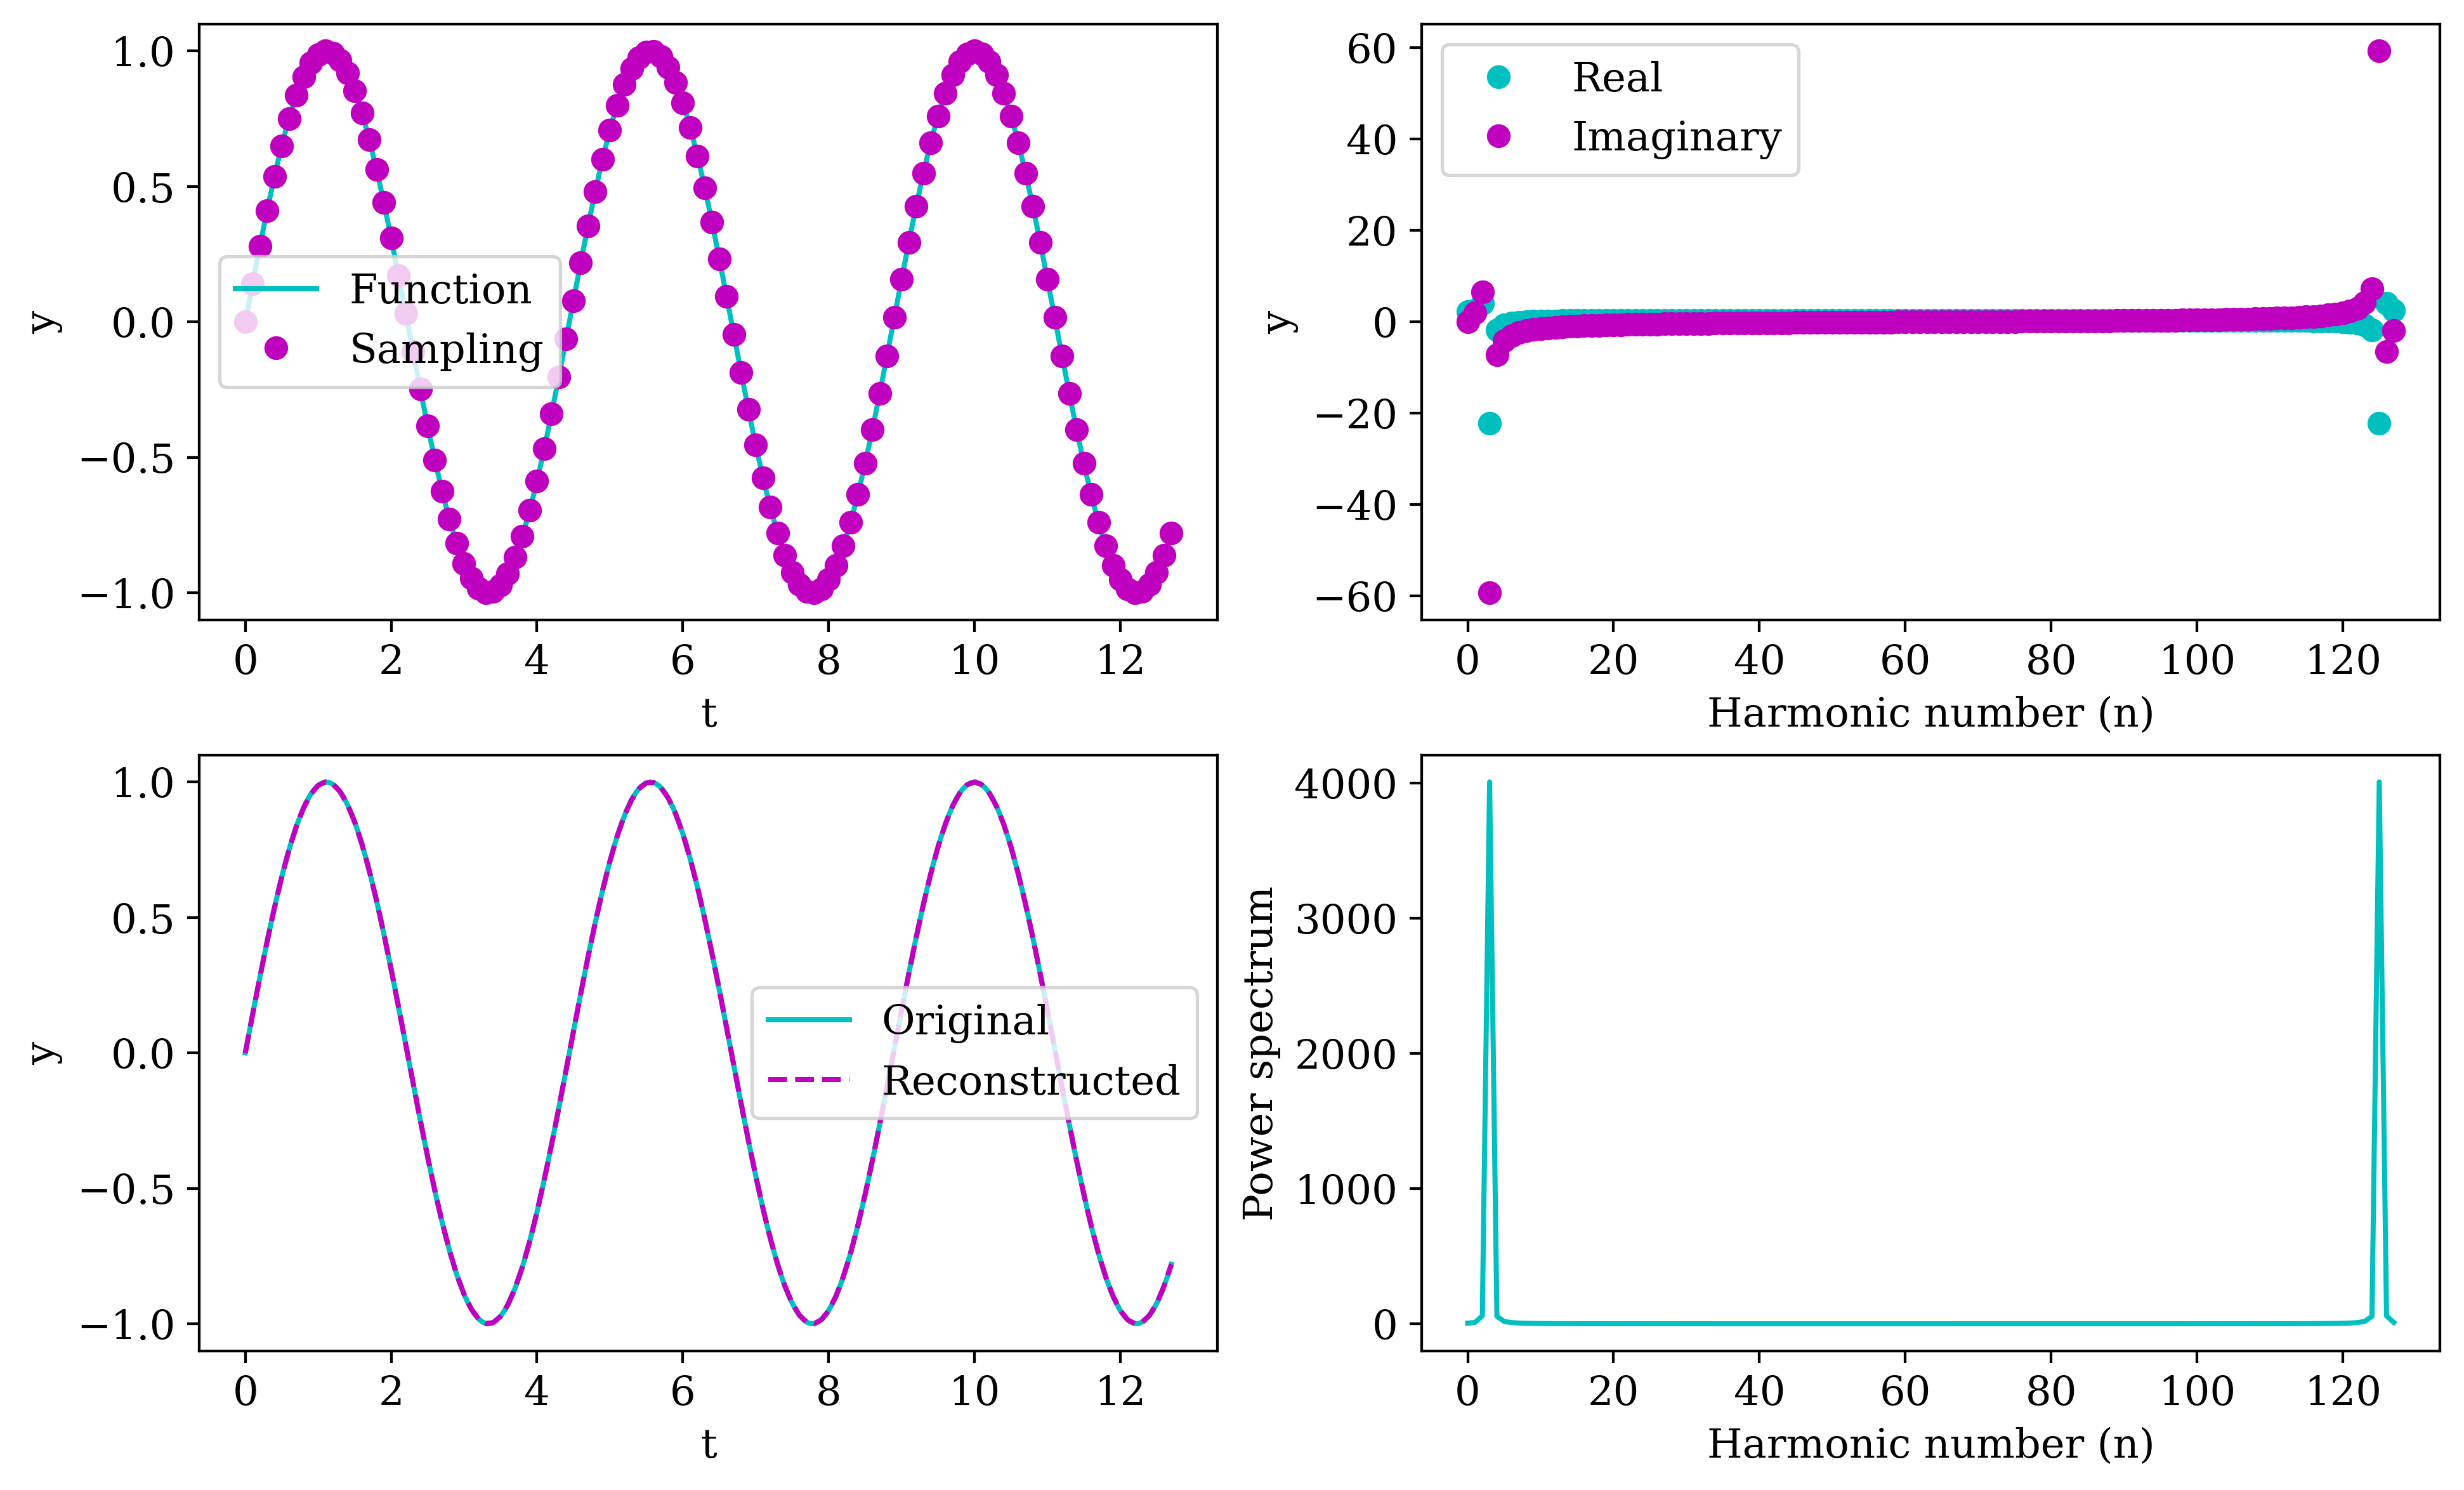

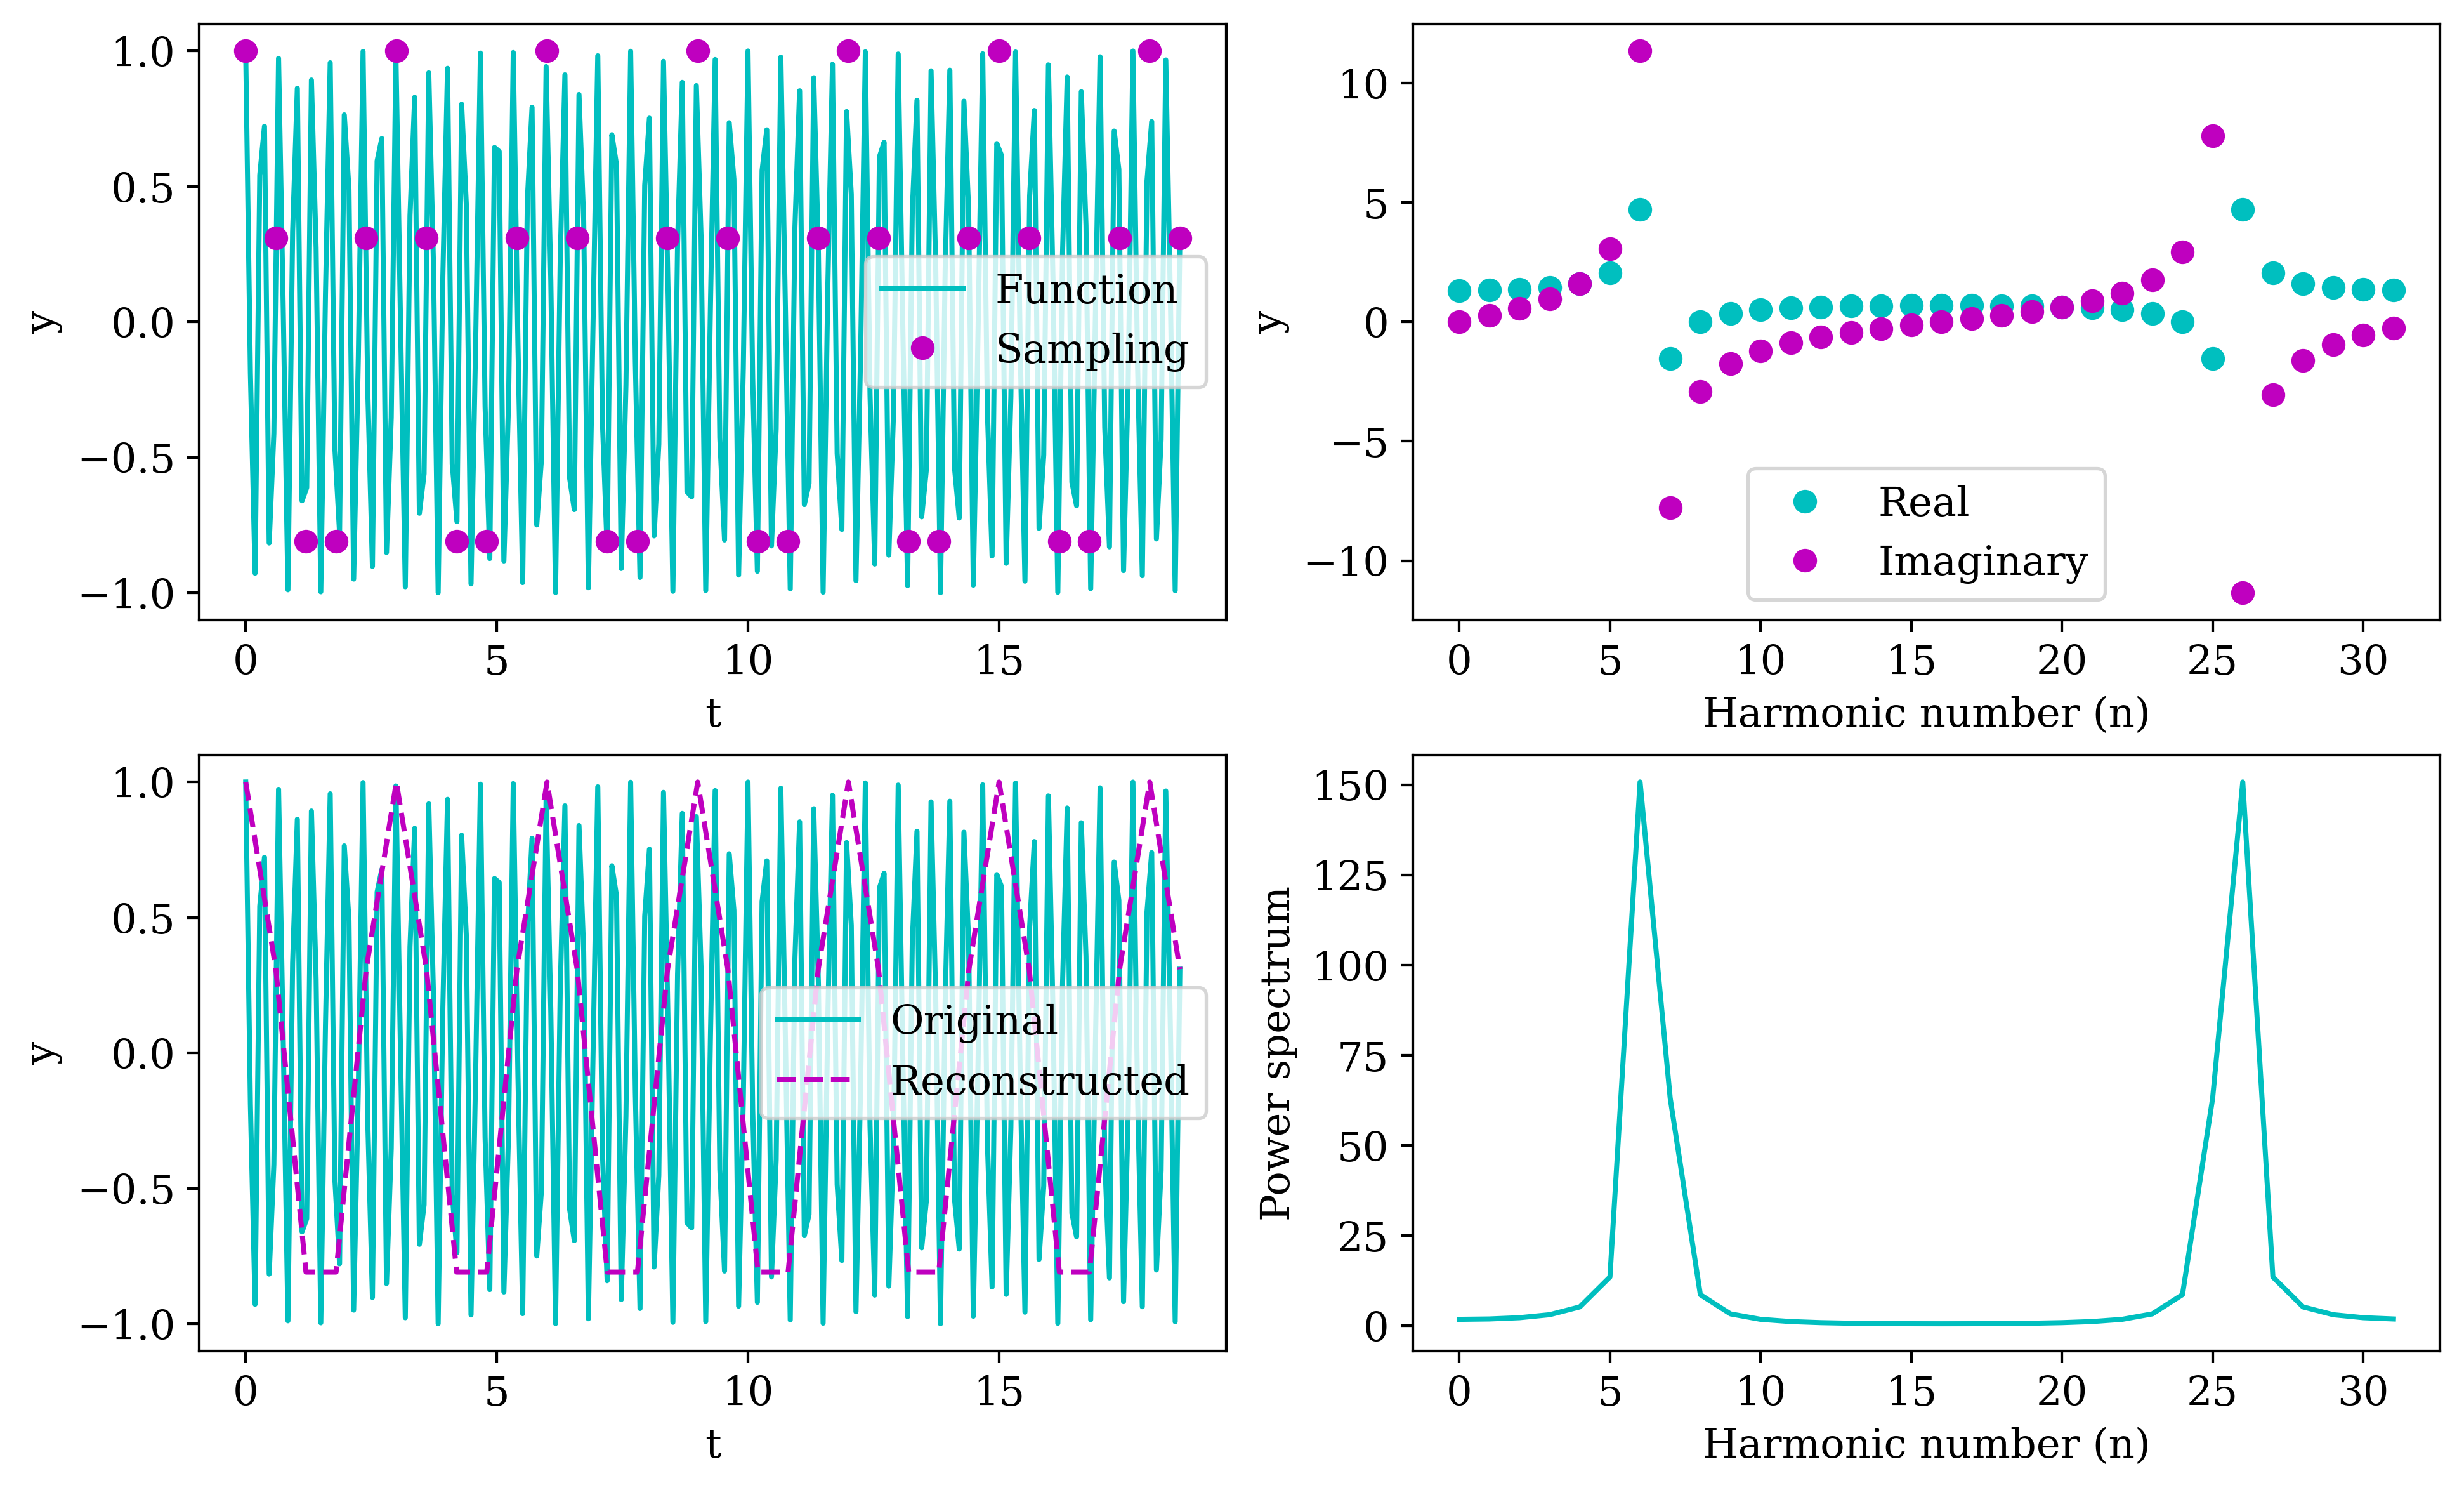

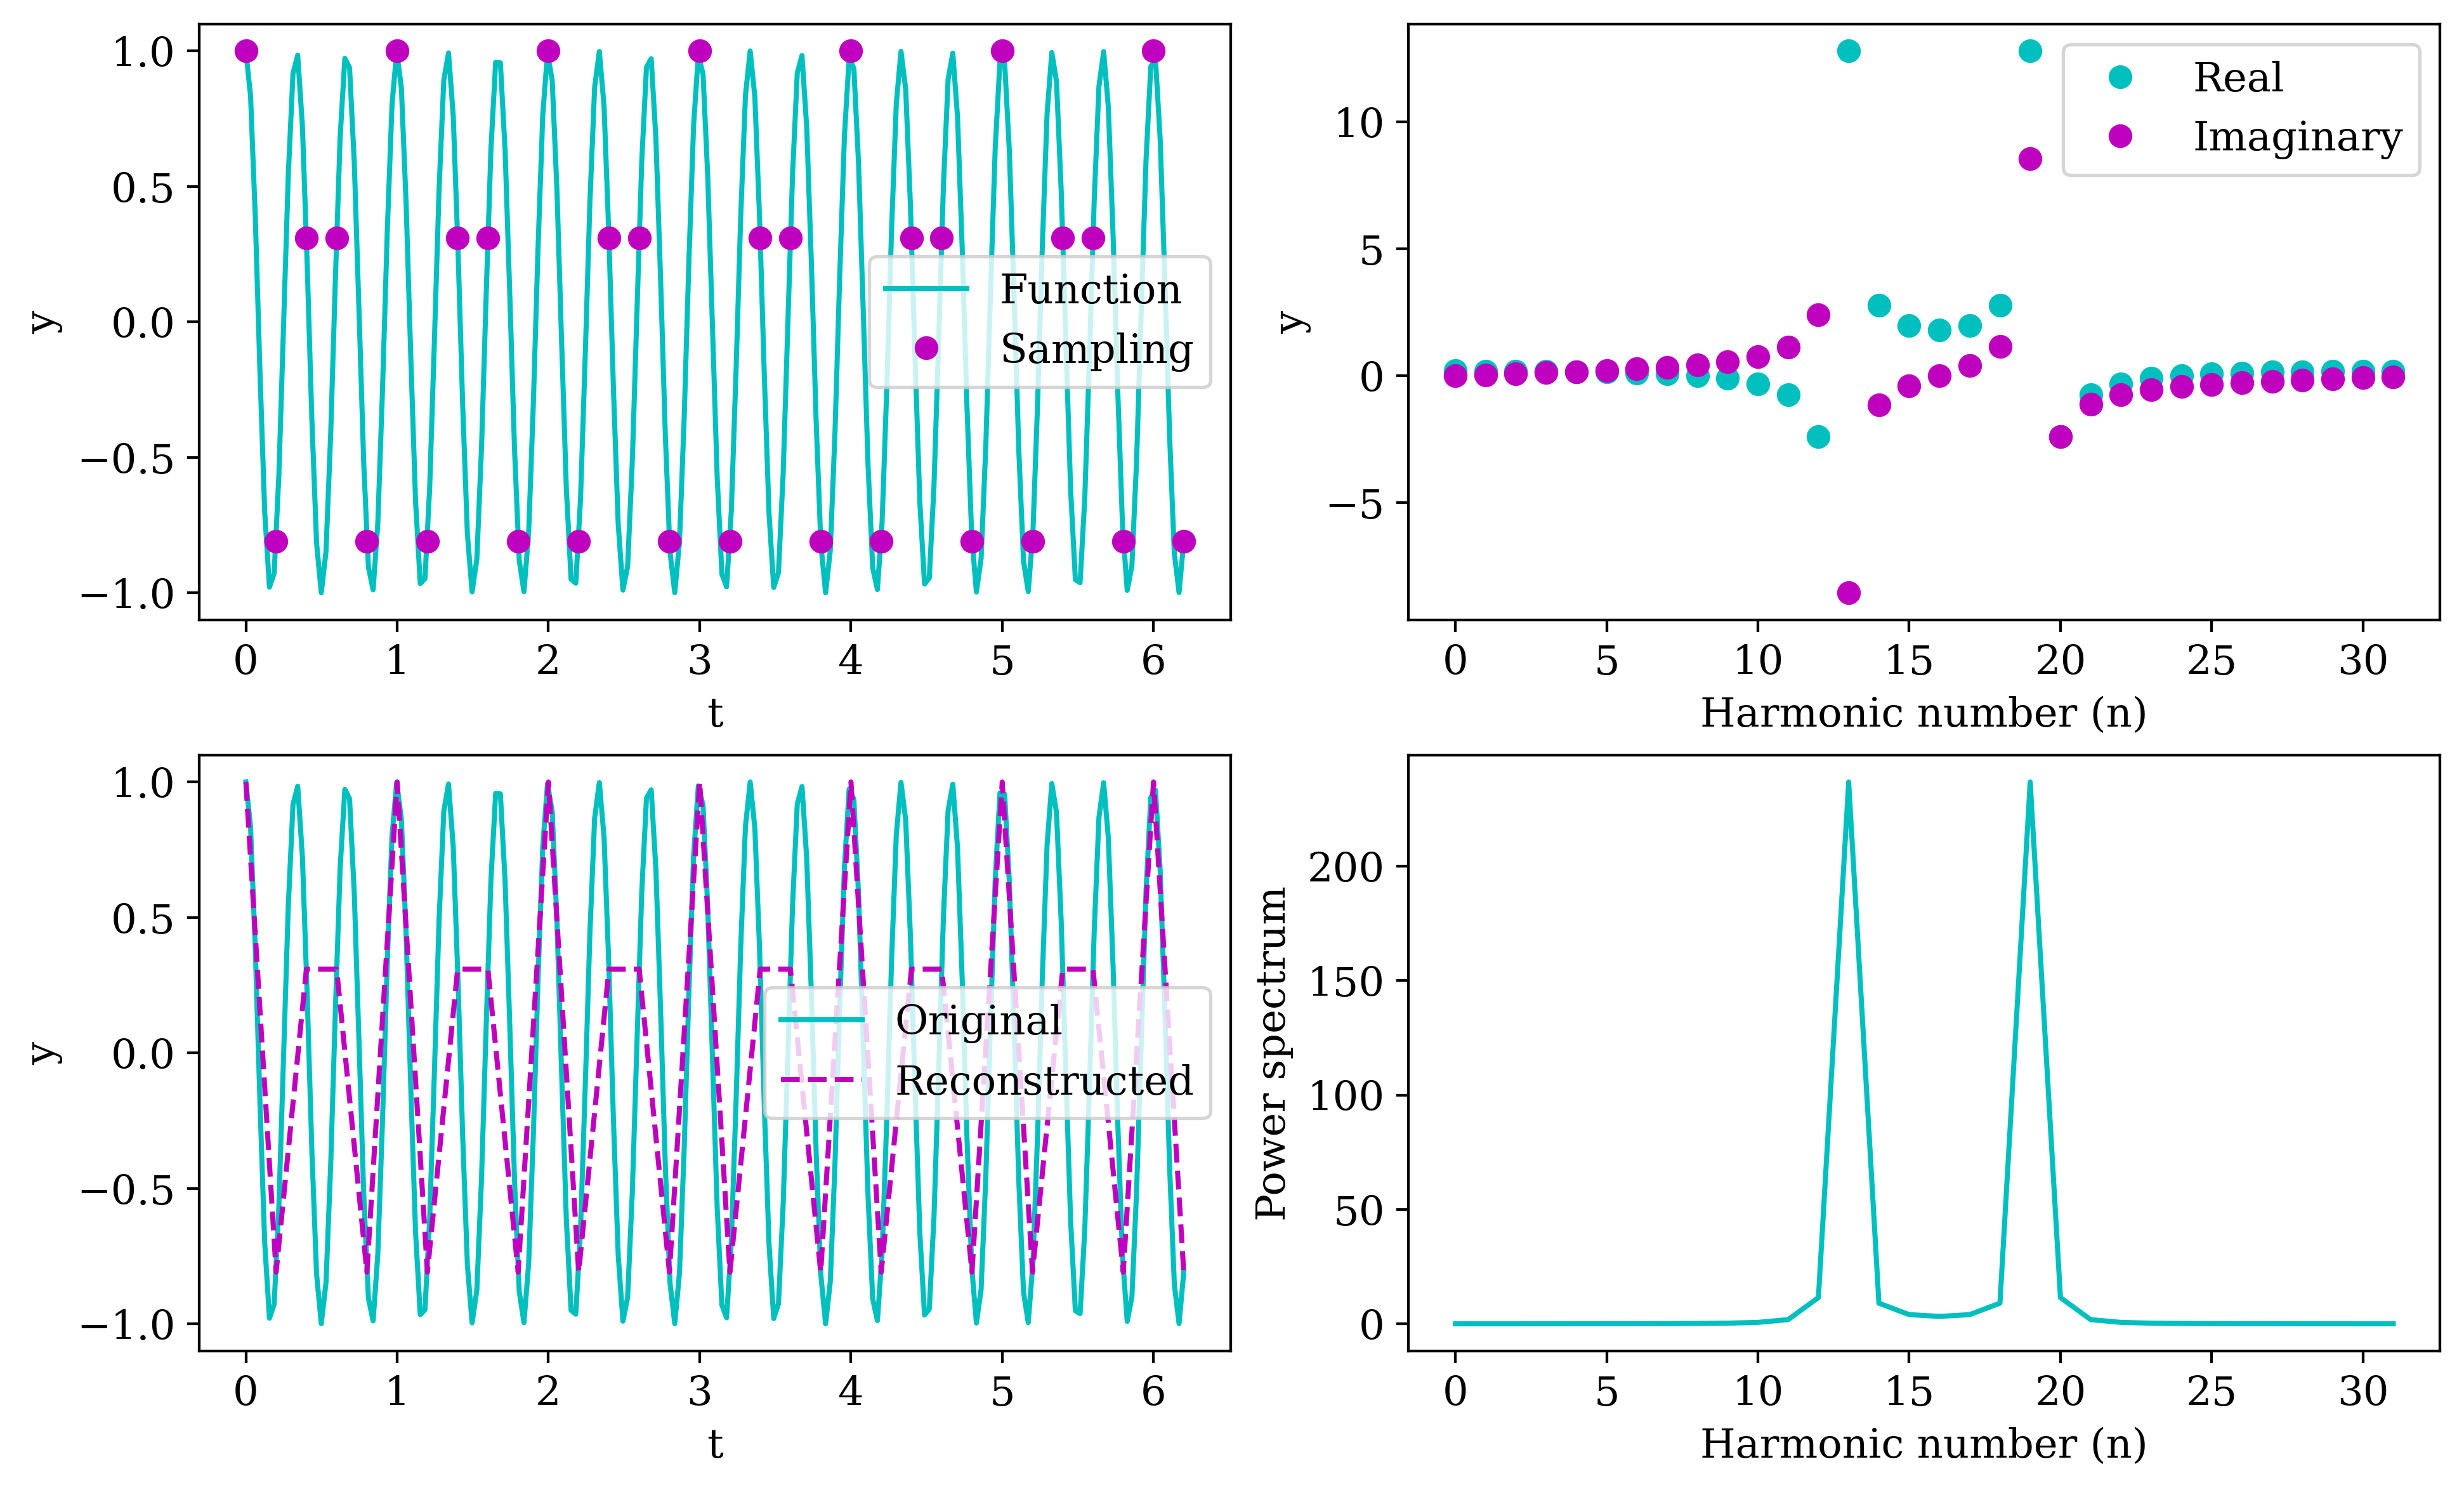

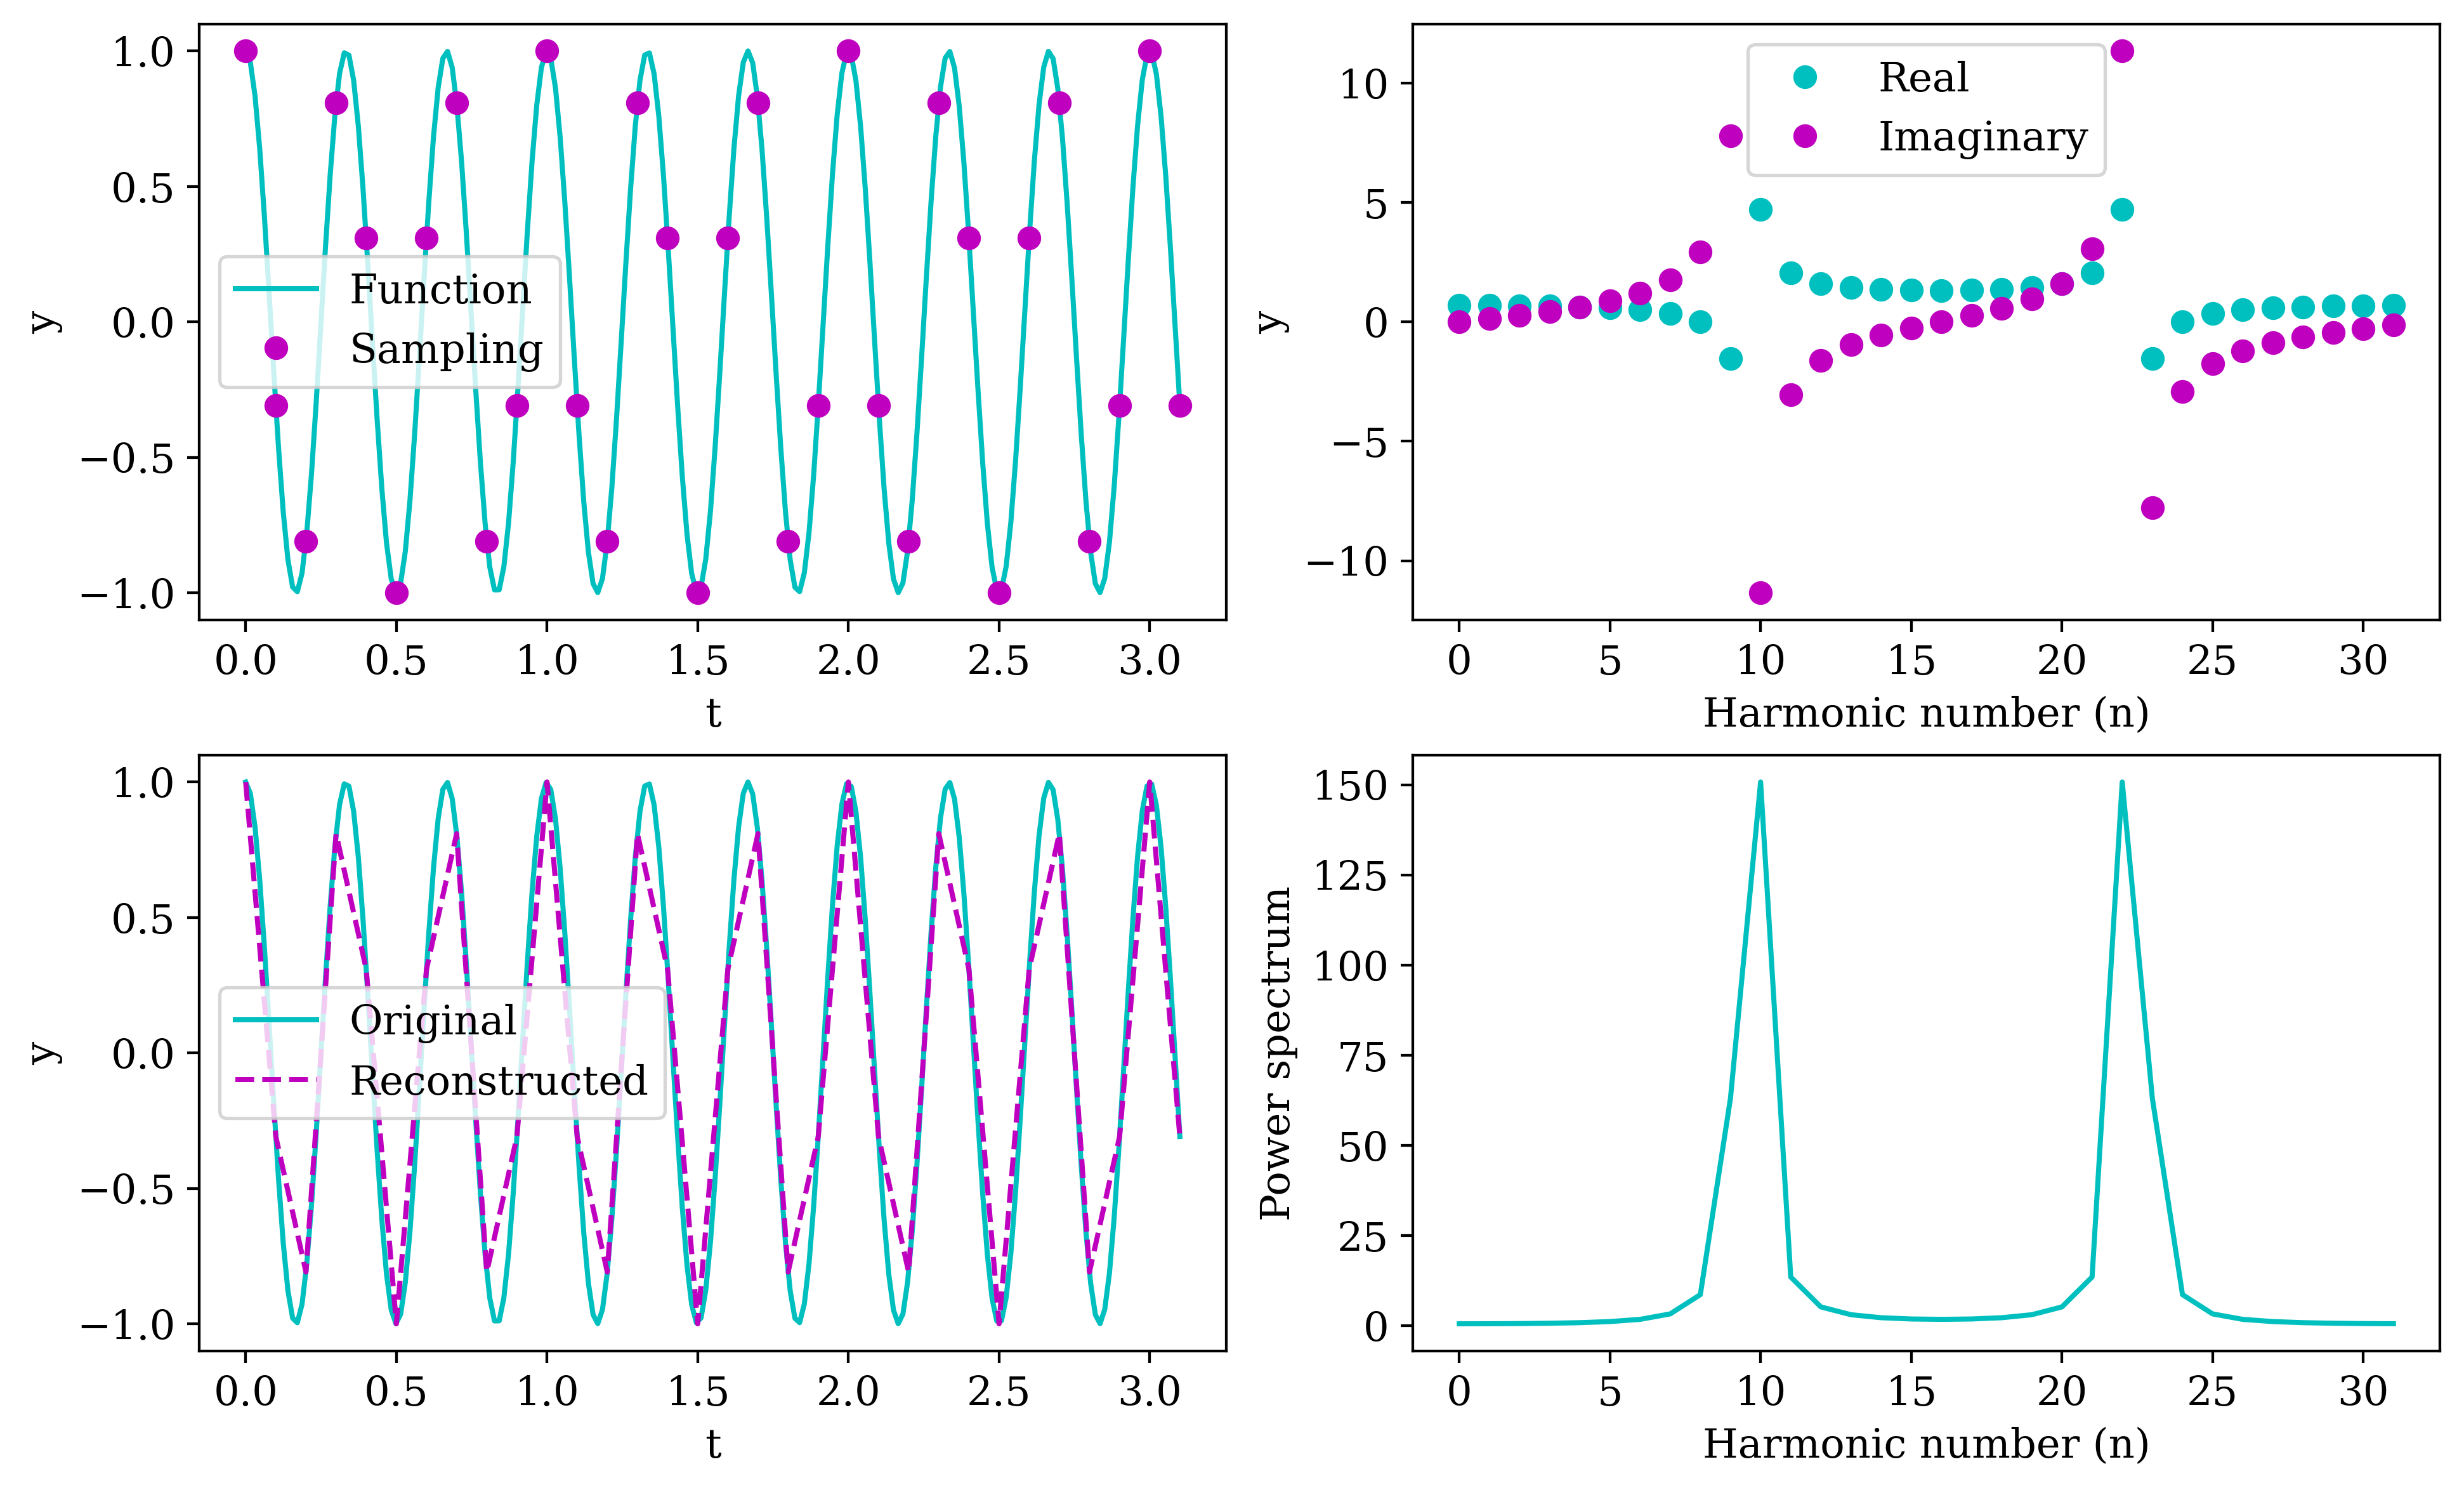

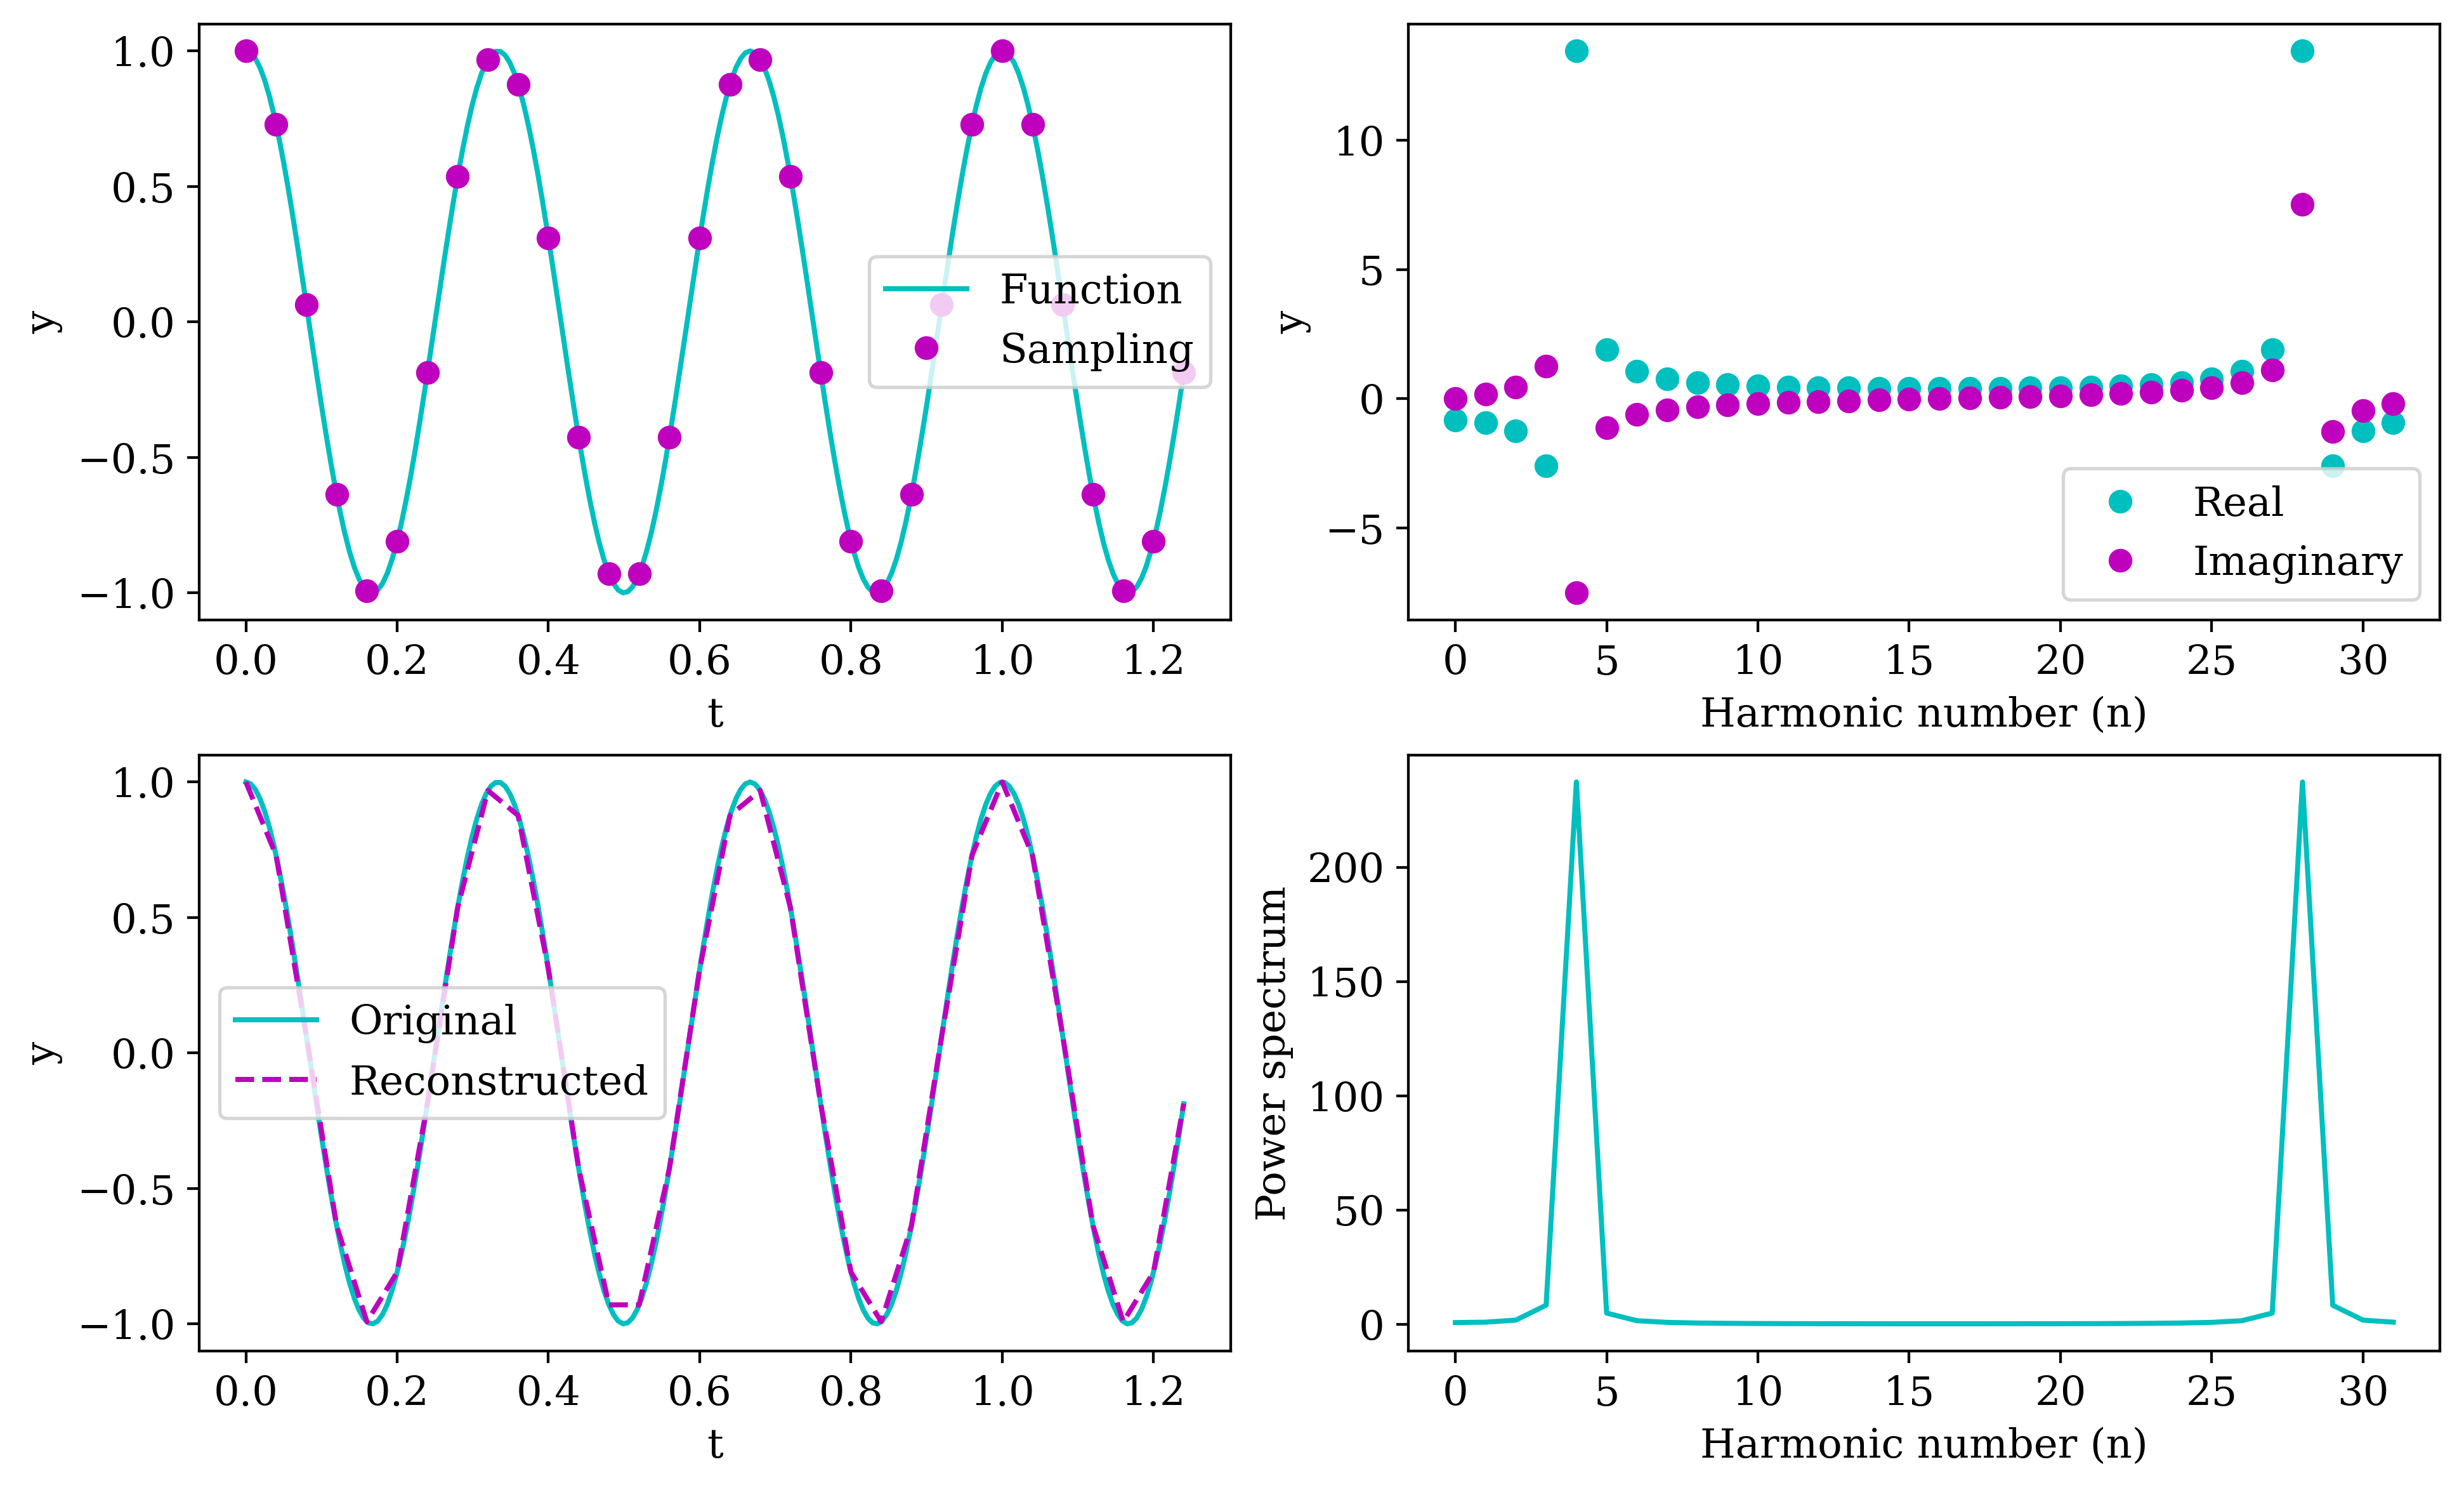

In [4]:
def real(f, N, n):
  return sum(f(m) * np.cos(2 * np.pi * m * n / N) for m in range(N))


def imag(f, N, n):
  return sum(-f(m) * np.sin(2 * np.pi * m * n / N) for m in range(N))


def reconstruct(f, N, m):
  return (1 / N) * sum(real(f, N, n) * np.cos(2 * np.pi * m * n / N)
                       - imag(f, N, n) * np.sin(2 * np.pi * m * n / N)
                       for n in range(N))


def plot(F, N, h, name):
  ts = np.arange(N) * h
  ts_real = np.linspace(0, (N - 1) * h, num=200)

  fig, axs = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True,
                          dpi=384)

  axs[0,0].plot(ts_real, F(ts_real), label='Function', color='c')
  axs[0,0].plot(ts, F(ts), 'mo', label='Sampling')
  axs[0,0].legend()
  axs[0,0].set_xlabel('t')
  axs[0,0].set_ylabel('y')

  f = lambda m: F(m * h)
  ns = np.arange(N)

  real_values = np.array([real(f, N, n) for n in range(N)])
  imag_values = np.array([imag(f, N, n) for n in range(N)])

  axs[0,1].plot(ns, real_values, 'co', label='Real')
  axs[0,1].plot(ns, imag_values, 'mo', label='Imaginary')
  axs[0,1].legend()
  axs[0,1].set_xlabel('Harmonic number (n)')
  axs[0,1].set_ylabel('y')

  axs[1,0].plot(ts_real, F(ts_real), label='Original', color='c')
  axs[1,0].plot(ts, [reconstruct(f, N, m) for m in range(N)], 'm--',
                label='Reconstructed')
  axs[1,0].legend()
  axs[1,0].set_xlabel('t')
  axs[1,0].set_ylabel('y')

  P = real_values**2 + imag_values**2

  axs[1,1].plot(ns, P, color='c')
  axs[1,1].set_xlabel('Harmonic number (n)')
  axs[1,1].set_ylabel('Power spectrum')

  plt.savefig(f'{name}.png', bbox_inches='tight')
  plt.show()


h, N = 0.1, 128
r = 1 / h
v1 = 1 / (N * h)

print(f'r={r}, v1={v1}\n')

F = lambda t: np.sin(0.45 * np.pi * t)
plot(F, N, h, 'sin')

F = lambda t: np.cos(6 * np.pi * t)
N = 32
hs = [0.6, 0.2, 0.1, 0.04]

for h in hs:
  plot(F, N, h, f'cos_{h}')